### Importing Necessary Libraries & Connecting to Drive

In [1]:
%%capture
!pip install mne
!pip install scipy
!pip install spektral

import mne
import numpy as np
from scipy.signal import welch
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from tensorflow.keras.models import load_model
import matplotlib.pyplot as plt
import io
from PIL import Image
from scipy.stats import skew, kurtosis
from collections import Counter

import tensorflow as tf
import keras
from keras import ops, Input, Model
from keras.layers import Dropout, Dense, Flatten, TimeDistributed, GlobalAveragePooling1D, Lambda
from keras.optimizers import Adam
from keras.regularizers import l2
from spektral.layers import GCNConv

In [2]:
import os
import sys

# Dual-environment path auto-configuration (Google Colab vs Local Windows/Linux IDE)
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    target_dir = '/content/drive/MyDrive/Alpha Band Analysis/Alpha Band Detection'
    if os.path.exists(target_dir):
        os.chdir(target_dir)
else:
    local_candidates = [
        os.path.abspath(r'e:/Obaidul Haque/Alpha Band Analysis/Alpha Band Detection'),
        os.path.abspath('./Alpha Band Analysis/Alpha Band Detection'),
        os.path.abspath('.')
    ]
    for p in local_candidates:
        if os.path.exists(p) and 'Alpha Band Detection' in p:
            os.chdir(p)
            break

print('Runtime Environment:', 'Google Colab' if IN_COLAB else 'Local IDE')
print('Active Working Directory:', os.getcwd())


Mounted at /content/drive
/content/drive/MyDrive/Alpha Band Analysis/Alpha Band Detection


In [3]:
import os
import sys

test_candidates = [
    os.path.abspath('./Preprocessed Data/testing'),
    os.path.abspath(r'e:/Obaidul Haque/Alpha Band Analysis/Alpha Band Detection/Preprocessed Data/testing'),
    '/content/drive/MyDrive/Alpha Band Analysis/Alpha Band Detection/Preprocessed Data/testing'
]
test_dir = next((p for p in test_candidates if os.path.exists(p)), test_candidates[0])
avail_files = sorted(os.listdir(test_dir)) if os.path.exists(test_dir) else []
print(f'Available Test Cohort Files ({len(avail_files)} files):')
print(avail_files[:8], '...')

default_file = 'chb12_08.edf'
if sys.stdin.isatty():
    try:
        user_in = input(f'Enter the edf filename [default: {default_file}]: ').strip()
        filename = user_in.replace('csv', 'edf') if user_in else default_file
    except Exception:
        filename = default_file
else:
    filename = default_file

print('Selected File for Inference:', filename)


chb01_26.csv   chb07_19.csv  chb12_36.csv   chb20_14.csv  chb24_17.csv
chb02_16.csv   chb08_02.csv  chb14_04.csv   chb21_22.csv
chb02_16+.csv  chb08_11.csv  chb14_06.csv   chb22_38.csv
chb03_35.csv   chb12_06.csv  chb17a_04.csv  chb24_13.csv
chb05_17.csv   chb12_09.csv  chb19_29.csv   chb24_15.csv
Enter the edf filename: chb01_26.csv
Selected File: chb01_26.edf


### Preparing Data for Inference

#### Loading EDF file & Filtering

In [4]:
channel_to_keep = [
    'FP1-F7',
    'F7-T7',
    'T7-P7',
    'P7-O1',
    'FP1-F3',
    'F3-C3',
    'C3-P3',
    'P3-O1',
    'FP2-F4',
    'F4-C4',
    'C4-P4',
    'P4-O2',
    'FP2-F8',
    'F8-T8',
    'T8-P8-0',
    'P8-O2',
    'FZ-CZ',
    'CZ-PZ',
    'P7-T7',
    'T7-FT9',
    'FT9-FT10',
    'FT10-T8',
    'T8-P8-1'
]

seizure_times_dict = {
    # Seizure
    'chb01_03.edf': [(2996, 3036)],
    'chb01_04.edf': [(1467, 1494)],
    'chb01_15.edf': [(1732, 1772)],
    'chb01_16.edf': [(1015, 1066)],
    'chb01_18.edf': [(1720, 1810)],
    'chb01_21.edf': [(327, 420)],
    'chb01_26.edf': [(1862, 1963)],
    'chb02_16.edf': [(130, 212)],
    'chb02_16+.edf': [(2972, 3053)],
    'chb02_19.edf': [(3369, 3378)],
    'chb03_01.edf': [(362, 414)],
    'chb03_02.edf': [(731, 796)],
    'chb03_03.edf': [(432, 501)],
    'chb03_04.edf': [(2162, 2214)],
    'chb03_34.edf': [(1982, 2029)],
    'chb03_35.edf': [(2592, 2656)],
    'chb03_36.edf': [(1725, 1778)],
    'chb04_05.edf': [(7804, 7853)],
    'chb04_08.edf': [(6446, 6557)],
    'chb04_28.edf': [(1679, 1781), (3782, 3898)],
    'chb05_06.edf': [(417, 532)],
    'chb05_13.edf': [(1086, 1196)],
    'chb05_16.edf': [(2317, 2413)],
    'chb05_17.edf': [(2451, 2571)],
    'chb05_22.edf': [(2348, 2465)],
    'chb07_12.edf': [(4920, 5006)],
    'chb07_13.edf': [(3285, 3381)],
    'chb07_19.edf': [(13688, 13831)],
    'chb08_02.edf': [(2670, 2841)],
    'chb08_05.edf': [(2856, 3046)],
    'chb08_11.edf': [(2988, 3122)],
    'chb08_13.edf': [(2417, 2577)],
    'chb08_21.edf': [(2083, 2347)],
    'chb10_12.edf': [(6313, 6348)],
    'chb10_20.edf': [(6888, 6958)],
    'chb10_27.edf': [(2382, 2447)],
    'chb10_30.edf': [(3021, 3079)],
    'chb10_31.edf': [(3801, 3877)],
    'chb10_38.edf': [(4618, 4707)],
    'chb10_89.edf': [(1383, 1437)],
    'chb11_82.edf': [(298, 320)],
    'chb11_92.edf': [(2695, 2727)],
    'chb11_99.edf': [(1454, 2206)],
    'chb12_06.edf': [(1665, 1726), (3415, 3447)],
    'chb12_08.edf': [(1426, 1439), (1591, 1614), (1957, 1977), (2798, 2824)],
    'chb12_09.edf': [(3082, 3114), (3503, 3535)],
    'chb12_10.edf': [(593, 625), (811, 856)],
    'chb12_11.edf': [(1085, 1122)],
    'chb12_23.edf': [(253, 333), (425, 522), (630, 670)],
    'chb12_33.edf': [(2185, 2206), (2427, 2450)],
    'chb12_36.edf': [(653, 680)],
    'chb12_38.edf': [(1548, 1573), (2798, 2821), (2966, 3009), (3146, 3201), (3364, 3410)],
    'chb12_42.edf': [(699, 750), (945, 973), (1170, 1199), (1676, 1701), (2213, 2236)],
    'chb13_19.edf': [(2077, 2121)],
    'chb13_21.edf': [(934, 1004)],
    'chb13_55.edf': [(458, 478), (2436, 2454)],
    'chb13_58.edf': [(2474, 2491)],
    'chb13_59.edf': [(3339, 3401)],
    'chb13_60.edf': [(638, 660)],
    'chb13_62.edf': [(851, 916), (1626, 1691), (2664, 2721)],
    'chb14_03.edf': [(1986, 2000)],
    'chb14_04.edf': [(1372, 1392), (2817, 2839)],
    'chb14_06.edf': [(1911, 1925)],
    'chb14_11.edf': [(1838, 1879)],
    'chb14_17.edf': [(3239, 3259)],
    'chb14_18.edf': [(1039, 1061)],
    'chb14_27.edf': [(2833, 2849)],
    'chb17a_03.edf': [(2282, 2372)],
    'chb17a_04.edf': [(3025, 3140)],
    'chb17b_63.edf': [(3136, 3224)],
    'chb18_29.edf': [(3477, 3527)],
    'chb18_30.edf': [(541, 571)],
    'chb18_31.edf': [(2087, 2155)],
    'chb18_32.edf': [(1908, 1963)],
    'chb18_35.edf': [(2196, 2264)],
    'chb18_36.edf': [(463, 509)],
    'chb19_28.edf': [(299, 377)],
    'chb19_29.edf': [(2964, 3041)],
    'chb19_30.edf': [(3159, 3240)],
    'chb20_12.edf': [(94, 123)],
    'chb20_13.edf': [(1440, 1470), (2498, 2537)],
    'chb20_14.edf': [(1971, 2009)],
    'chb20_15.edf': [(390, 425), (1689, 1738)],
    'chb20_16.edf': [(2226, 2261)],
    'chb20_68.edf': [(1393, 1432)],
    'chb21_19.edf': [(1288, 1344)],
    'chb21_20.edf': [(2627, 2677)],
    'chb21_21.edf': [(2003, 2084)],
    'chb21_22.edf': [(2553, 2565)],
    'chb22_20.edf': [(3367, 3425)],
    'chb22_25.edf': [(3139, 3213)],
    'chb22_38.edf': [(1263, 1335)],
    'chb24_01.edf': [(480, 505), (2451, 2476)],
    'chb24_03.edf': [(231, 260), (2883, 2908)],
    'chb24_04.edf': [(1088, 1120), (1411, 1438), (1745, 1764)],
    'chb24_06.edf': [(1229, 1253)],
    'chb24_07.edf': [(38, 60)],
    'chb24_09.edf': [(1745, 1764)],
    'chb24_11.edf': [(3527, 3597)],
    'chb24_13.edf': [(3288, 3304)],
    'chb24_14.edf': [(1939, 1966)],
    'chb24_15.edf': [(3552, 3569)],
    'chb24_17.edf': [(3515, 3581)],
    'chb24_18.edf': [(3515, 3581)],
    'chb24_21.edf': [(2804, 2872)],
}

edf_file_path = f'/content/drive/MyDrive/Alpha Band Analysis/Dataset/Training/{"Seizure" if len(seizure_times_dict[filename]) is not 0 else "Non Seizure"}/{filename}'

raw = None
# 1. Load data using mne
try:
    raw = mne.io.read_raw_edf(edf_file_path, preload=True)
    print("Data loaded successfully.")
except FileNotFoundError:
    print(f"Error: File not found at {edf_file_path}")
    exit()

# 2. Pick channels based on the specified channels list
try:
    raw_real = raw.copy()
    raw = raw.pick_channels(channel_to_keep)
    print(f"Selected channels: {raw.ch_names}")
except ValueError:
    print(f"Error: One or more channels in {channel_to_keep} not found in the EEG data.")
    exit()

# Filtering
print("\n--- Filtering ---")

# a) Bandpass filter (0.5 Hz to 4 Hz)
low_cutoff = 8
high_cutoff = 13
raw_filtered_bandpass = raw.copy().filter(l_freq=low_cutoff, h_freq=high_cutoff)
raw_real_filtered_bandpass = raw_real.copy().filter(l_freq=low_cutoff, h_freq=high_cutoff)
print(f"Bandpass filter applied (low={low_cutoff} Hz, high={high_cutoff} Hz).")

# b) Notch filter (remove powerline interference at 50)
powerline_freq = 50.0
raw_filtered_notch = raw_filtered_bandpass.copy().notch_filter(freqs=powerline_freq)
raw_real_filtered_notch = raw_real_filtered_bandpass.copy().notch_filter(freqs=powerline_freq)
print(f"Notch filter applied at {powerline_freq} Hz.")

<>:136: SyntaxWarning: "is not" with 'int' literal. Did you mean "!="?
<>:136: SyntaxWarning: "is not" with 'int' literal. Did you mean "!="?
/tmp/ipykernel_607/4134952094.py:136: SyntaxWarning: "is not" with 'int' literal. Did you mean "!="?
  edf_file_path = f'/content/drive/MyDrive/Alpha Band Analysis/Dataset/Training/{"Seizure" if len(seizure_times_dict[filename]) is not 0 else "Non Seizure"}/{filename}'


Extracting EDF parameters from /content/drive/MyDrive/Alpha Band Analysis/Dataset/Training/Seizure/chb01_26.edf...
Setting channel info structure...
Creating raw.info structure...


/tmp/ipykernel_607/4134952094.py:141: RuntimeWarning: Channel names are not unique, found duplicates for: {'T8-P8'}. Applying running numbers for duplicates.
  raw = mne.io.read_raw_edf(edf_file_path, preload=True)


Reading 0 ... 595199  =      0.000 ...  2324.996 secs...
Data loaded successfully.
NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).
Selected channels: ['FP1-F7', 'F7-T7', 'T7-P7', 'P7-O1', 'FP1-F3', 'F3-C3', 'C3-P3', 'P3-O1', 'FP2-F4', 'F4-C4', 'C4-P4', 'P4-O2', 'FP2-F8', 'F8-T8', 'T8-P8-0', 'P8-O2', 'FZ-CZ', 'CZ-PZ', 'P7-T7', 'T7-FT9', 'FT9-FT10', 'FT10-T8', 'T8-P8-1']

--- Filtering ---
Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 8 - 13 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 8.00
- Lower transition bandwidth: 2.00 Hz (-6 dB cutoff frequency: 7.00 Hz)
- Upper passband edge: 13.00 Hz
- Upper transition bandwidth: 3.25 Hz (-6 dB cutoff frequency: 14.62 Hz)
- Filter length: 423 samples (1.652 s)

Filtering raw dat

#### Segmentation


--- Segmentation ---
Window size: 6 seconds (1536 samples).
Overlap: 0.0% (Step size: 6.0 seconds, 1536 samples).
Seizure periods provided: [(1862, 1963)]

Number of segments created: 387
Identified 1 Ictal block(s): [(310, 327)]

--- Filtering segments based on proximity to seizure ---
Filtered segments: Kept 38 out of 387 total segments.

Label Distribution (after filtering):
  Normal (0):      20
  Ictal (1):   18

--- Visualizing Segments from Each Class ---

Found 20 segments for class 'Normal'. Visualizing 5 of them...
Not setting metadata
1 matching events found
No baseline correction applied
0 projection items activated
Class: Normal (Label 0) - Example 1
Using matplotlib as 2D backend.


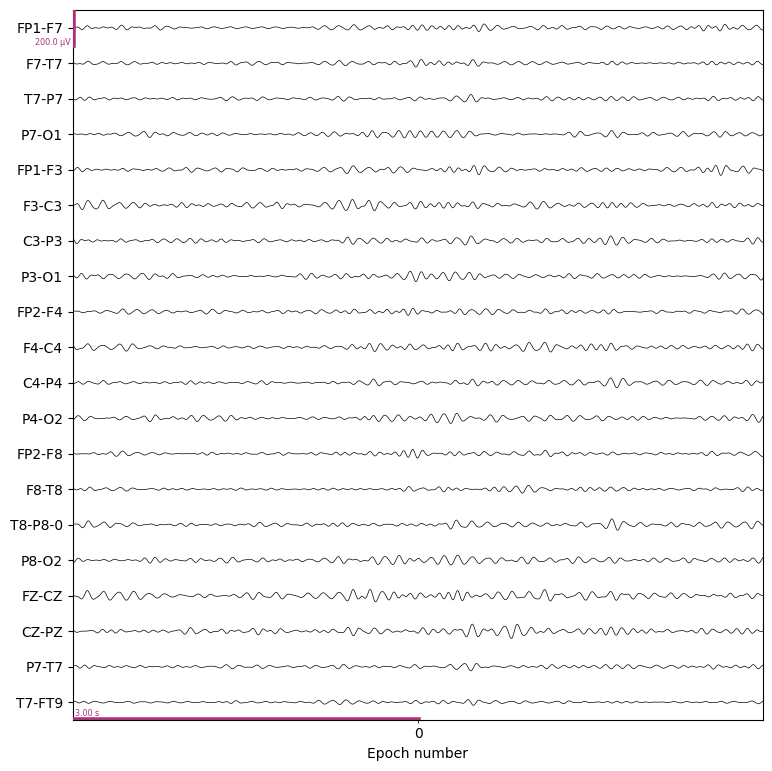

Not setting metadata
1 matching events found
No baseline correction applied
0 projection items activated
Class: Normal (Label 0) - Example 2


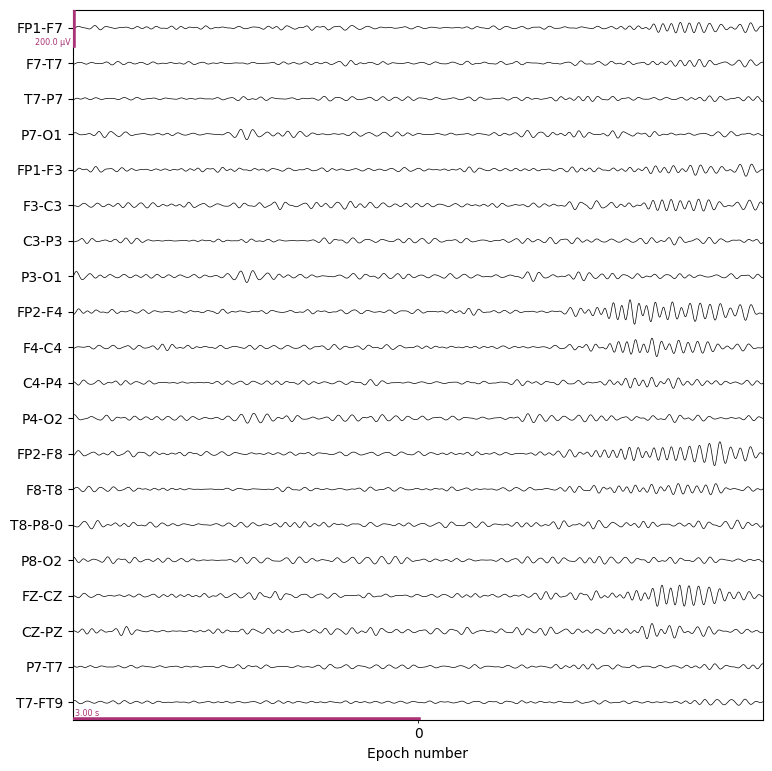

Not setting metadata
1 matching events found
No baseline correction applied
0 projection items activated
Class: Normal (Label 0) - Example 3


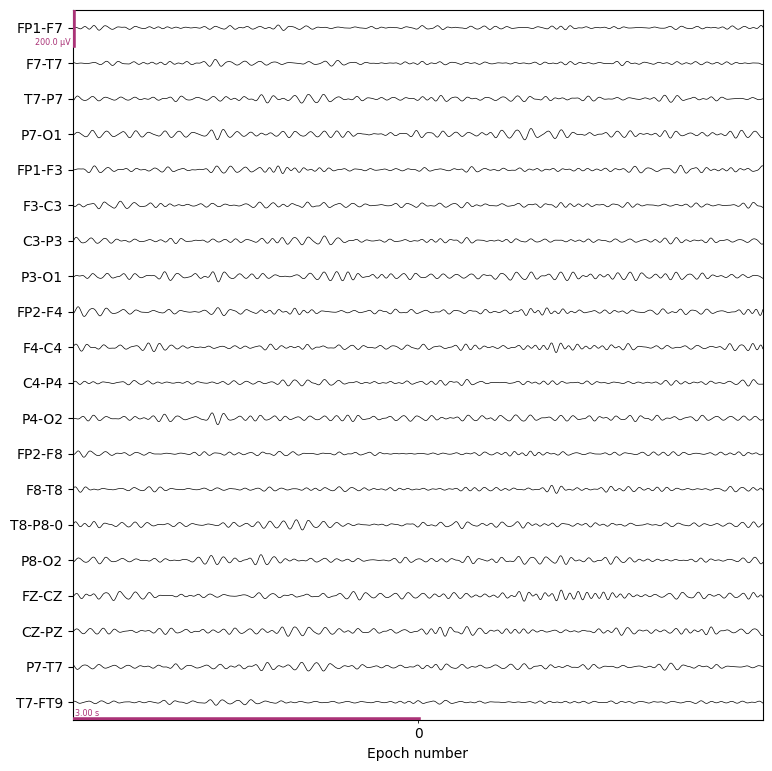

Not setting metadata
1 matching events found
No baseline correction applied
0 projection items activated
Class: Normal (Label 0) - Example 4


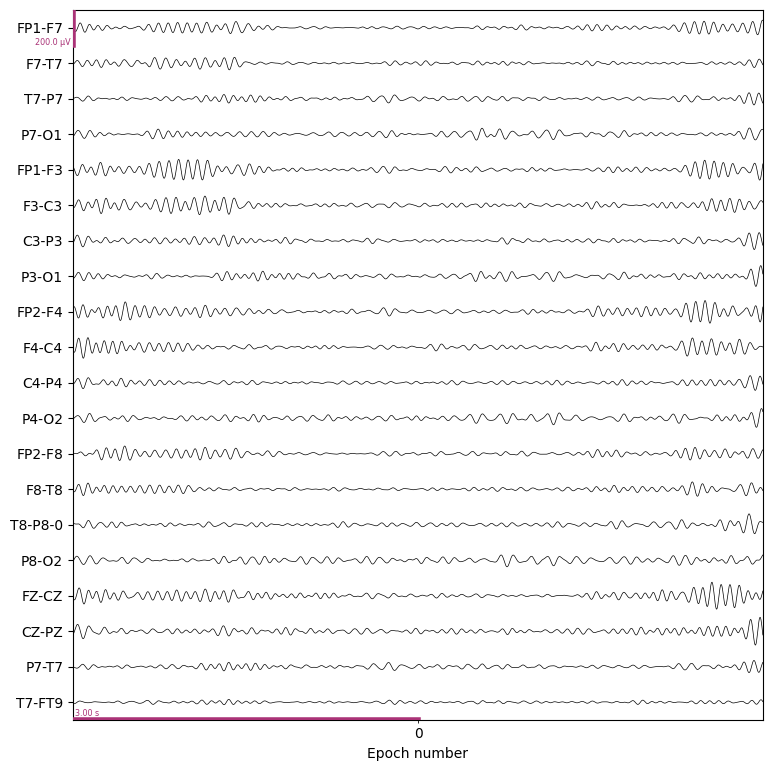

Not setting metadata
1 matching events found
No baseline correction applied
0 projection items activated
Class: Normal (Label 0) - Example 5


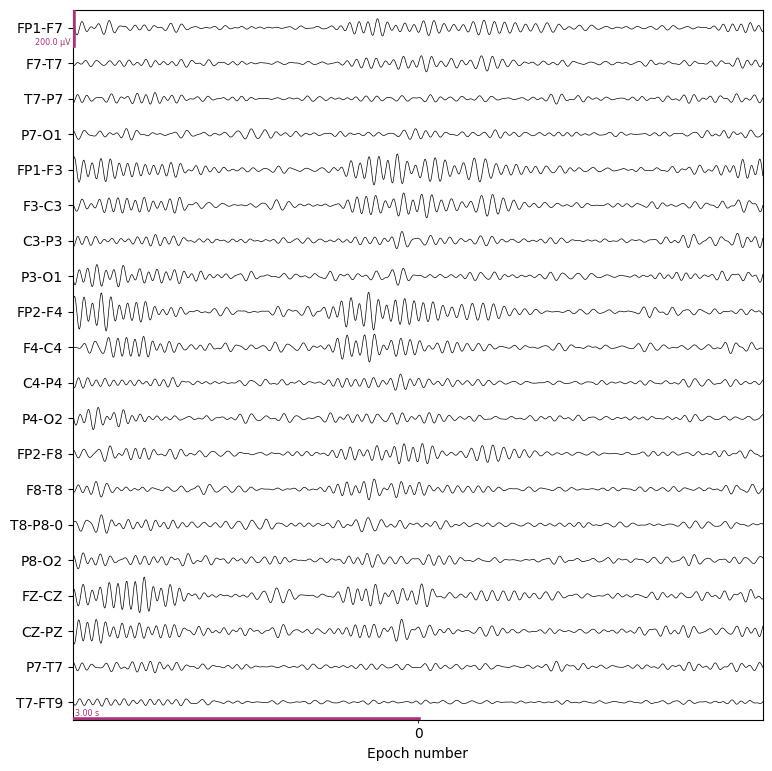


Found 18 segments for class 'Ictal'. Visualizing 5 of them...
Not setting metadata
1 matching events found
No baseline correction applied
0 projection items activated
Class: Ictal (Label 1) - Example 1


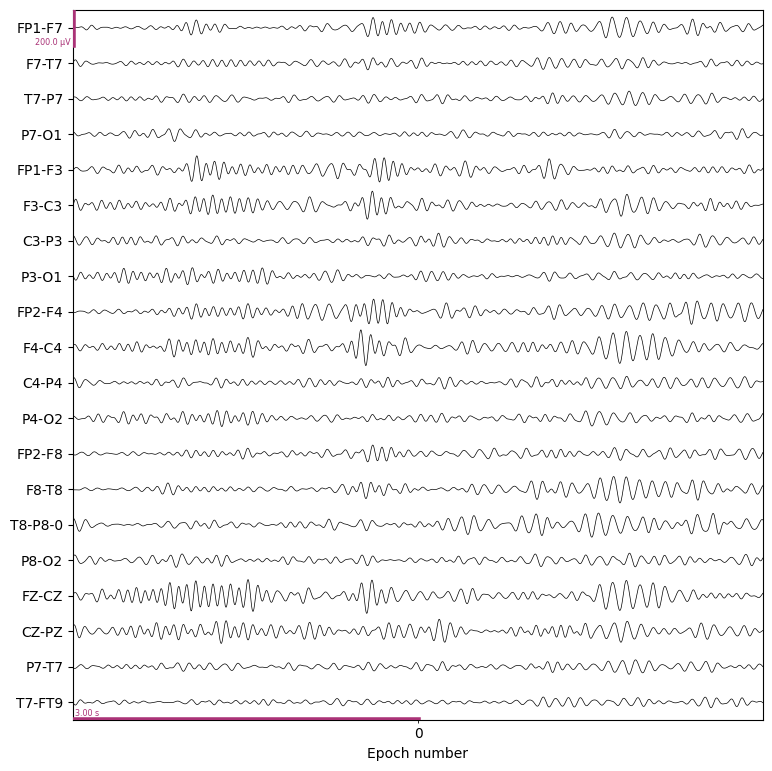

Not setting metadata
1 matching events found
No baseline correction applied
0 projection items activated
Class: Ictal (Label 1) - Example 2


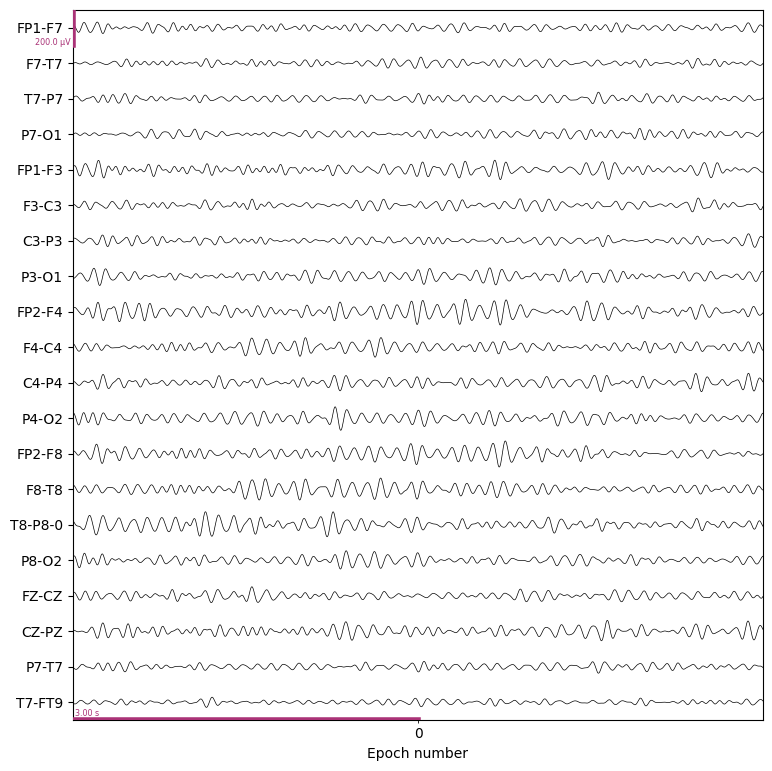

Not setting metadata
1 matching events found
No baseline correction applied
0 projection items activated
Class: Ictal (Label 1) - Example 3


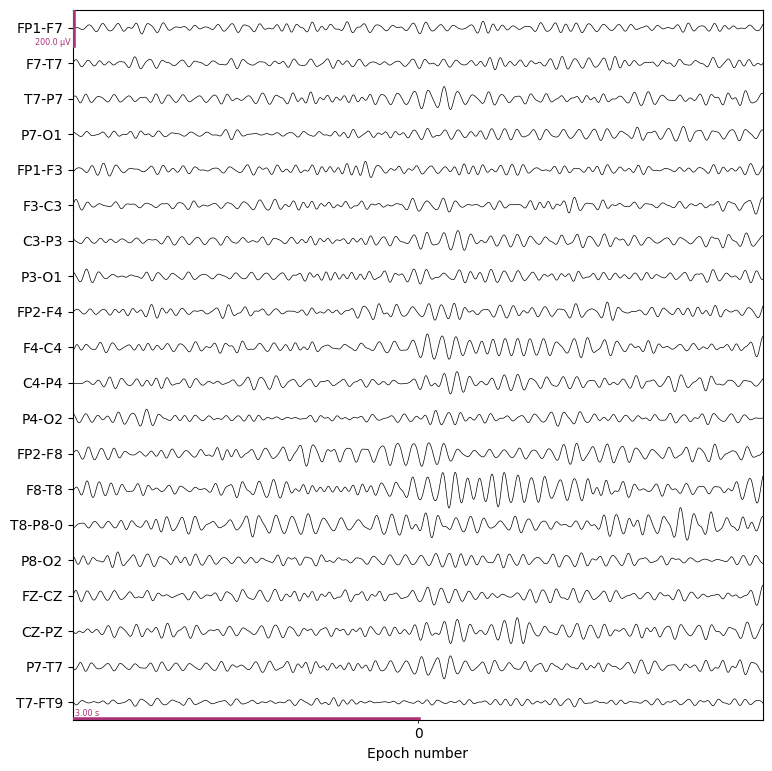

Not setting metadata
1 matching events found
No baseline correction applied
0 projection items activated
Class: Ictal (Label 1) - Example 4


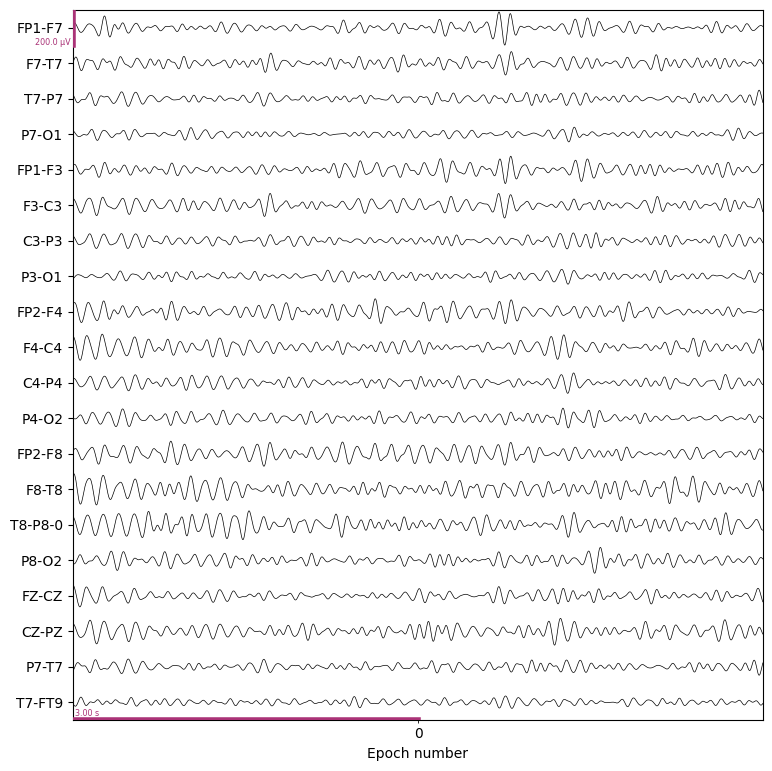

Not setting metadata
1 matching events found
No baseline correction applied
0 projection items activated
Class: Ictal (Label 1) - Example 5


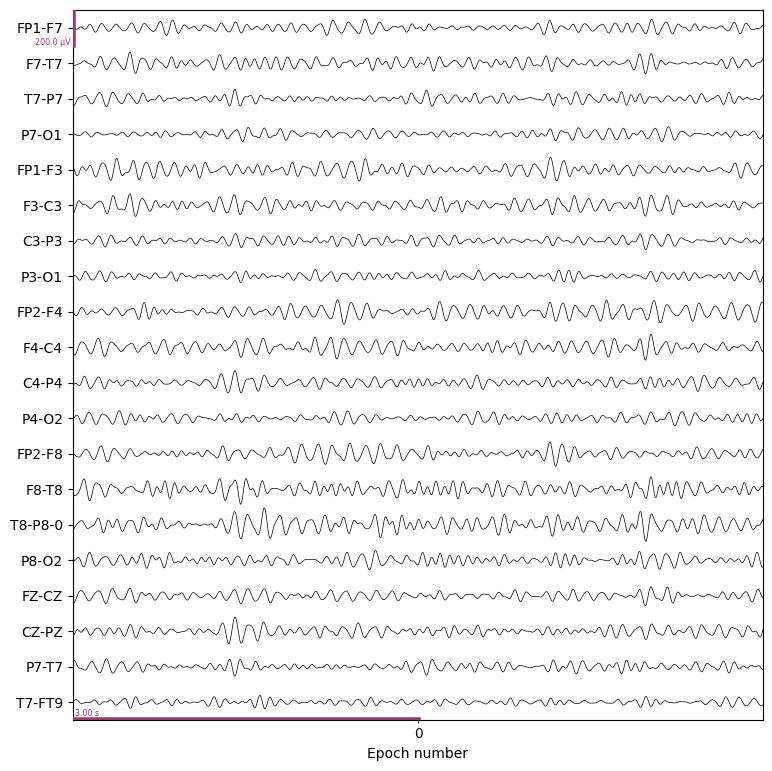

In [5]:
def segmentation(raw_filtered_notch, window_size_seconds, overlap_fraction, filename, seizure_periods_dict):
  """
  Segments EEG data, labels it, and filters it to keep only data
  proximal to seizures.

  Labels are defined as:
  0: Normal (kept only if within 10 segments of a pre-ictal or post-ictal period)
  1: Ictal (seizure segments)

  Args:
      raw_filtered_notch (mne.io.Raw): The preprocessed EEG data.
      window_size_seconds (float): The duration of each segment in seconds.
      overlap_fraction (float): The fraction of overlap between consecutive segments.
      filename (str): The name of the file being processed.
      seizure_periods_dict (dict): A dictionary mapping filenames to seizure start/end times.

  Returns:
      tuple: A tuple containing the filtered:
          - segments (list): List of 2D numpy arrays (segments).
          - labels (list): List of integer labels.
          - sfreq (float): The sampling frequency.
  """
  # --- Segmentation ---
  print("\n--- Segmentation ---")

  # a) Windowing
  sfreq = raw_filtered_notch.info['sfreq']
  window_size_samples = int(window_size_seconds * sfreq)
  print(f"Window size: {window_size_seconds} seconds ({window_size_samples} samples).")

  # b) Overlap
  step_size_seconds = window_size_seconds * (1 - overlap_fraction)
  step_size_samples = int(step_size_seconds * sfreq)
  print(f"Overlap: {overlap_fraction * 100}% (Step size: {step_size_seconds} seconds, {step_size_samples} samples).")

  data = raw_filtered_notch.get_data()
  n_channels, n_times = data.shape
  segments = []

  # c) Labeling
  try:
      seizure_periods = seizure_periods_dict[filename]
      print(f"Seizure periods provided: {seizure_periods}")

      # Create all segments first
      for i in range(0, n_times - window_size_samples + 1, step_size_samples):
          segment = data[:, i:i + window_size_samples]
          segments.append(segment)

      num_segments = len(segments)
      print(f"\nNumber of segments created: {num_segments}")
      labels = [0] * num_segments # Initialize all as Normal (0)

      # --- Labeling Pass 1: Ictal (1) ---
      ictal_indices = []
      for i in range(num_segments):
          segment_start_time = i * step_size_seconds
          segment_end_time = segment_start_time + window_size_seconds
          is_seizure = False
          for seizure_start, seizure_end in seizure_periods:
              if max(segment_start_time, seizure_start) < min(segment_end_time, seizure_end):
                  is_seizure = True
                  break
          if is_seizure:
              labels[i] = 1
              ictal_indices.append(i)

      if not ictal_indices:
          ictal_blocks = []
      else:
          ictal_blocks = []
          current_block_start = ictal_indices[0]
          for i in range(1, len(ictal_indices)):
              if ictal_indices[i] != ictal_indices[i-1] + 1:
                  ictal_blocks.append((current_block_start, ictal_indices[i-1]))
                  current_block_start = ictal_indices[i]
          ictal_blocks.append((current_block_start, ictal_indices[-1]))
      print(f"Identified {len(ictal_blocks)} Ictal block(s): {ictal_blocks}")

      # --- Filtering Pass: Keep only segments in and around seizures ---
      print("\n--- Filtering segments based on proximity to seizure ---")
      if not ictal_blocks:
          print("No seizure blocks found. All segments will be discarded.")
          return [], [], sfreq

      # Find all non-normal ("event") segments
      event_indices = [i for i, label in enumerate(labels) if label != 0]

      # Group event indices into contiguous blocks
      event_blocks = []
      if event_indices:
          block_start = event_indices[0]
          for i in range(1, len(event_indices)):
              if event_indices[i] != event_indices[i-1] + 1:
                  event_blocks.append((block_start, event_indices[i-1]))
                  block_start = event_indices[i]
          event_blocks.append((block_start, event_indices[-1]))

      # For each event block, define a window to keep (10 normal before, the block, 10 normal after)
      indices_to_keep = set()
      for start, end in event_blocks:
          window_start = max(0, start - 10)
          window_end = min(num_segments, end + 11)
          indices_to_keep.update(range(window_start, window_end))

      sorted_indices = sorted(list(indices_to_keep))
      final_segments = [segments[i] for i in sorted_indices]
      final_labels = [labels[i] for i in sorted_indices]

      print(f"Filtered segments: Kept {len(final_segments)} out of {num_segments} total segments.")

      if final_segments:
          print("\nLabel Distribution (after filtering):")
          print(f"  Normal (0):      {final_labels.count(0)}")
          print(f"  Ictal (1):   {final_labels.count(1)}")

      return final_segments, final_labels, sfreq

  except KeyError:
      print(f"{filename} seizure_periods_dict KeyError! 🛑🛑🛑🛑🛑🛑🛑")
      return None, None, None

# --- Main Execution ---
window_size_seconds = 6  # seconds
overlap_fraction = 0.0   # 0% overlap

# b) Get filename key
filename = edf_file_path.split("Seizure/")[-1]

# c) Perform Segmentation and Labeling
segments, labels, sfreq = segmentation(
    raw_filtered_notch=raw_filtered_notch,
    window_size_seconds=window_size_seconds,
    overlap_fraction=overlap_fraction,
    filename=filename,
    seizure_periods_dict=seizure_times_dict
)


# --- Visualize Segments from Each Class ---
print("\n--- Visualizing Segments from Each Class ---")

if segments:
    # Create MNE Info object once
    info = mne.create_info(ch_names=raw_filtered_notch.ch_names, sfreq=sfreq, ch_types='eeg')

    # Define labels for plotting
    class_map = {
        0: "Normal",
        1: "Ictal",
    }

    # Iterate through each class and plot up to 5 examples
    for class_label, class_name in class_map.items():
        # Find all indices in labels that match the current class
        indices_for_class = [i for i, label in enumerate(labels) if label == class_label]

        if not indices_for_class:
            print(f"\nNo segments found for class: {class_name} ({class_label})")
            continue

        # Limit to a maximum of 5 segments for visualization
        indices_to_plot = indices_for_class[:5]
        print(f"\nFound {len(indices_for_class)} segments for class '{class_name}'. Visualizing {len(indices_to_plot)} of them...")

        for i, segment_index in enumerate(indices_to_plot):
            # Get the segment data directly from the final list
            segment_data = segments[segment_index]

            # Reshape for MNE EpochsArray (1 epoch, n_channels, n_times)
            segment_data_reshaped = segment_data.reshape(1, segment_data.shape[0], segment_data.shape[1])

            # Create MNE EpochsArray
            epochs = mne.EpochsArray(segment_data_reshaped, info)

            # Plot the segment
            plot_title = f'Class: {class_name} (Label {class_label}) - Example {i+1}'
            print(plot_title)
            epochs.plot(scalings=0.0001, show=True, block=True, show_scrollbars=False, title=plot_title)

else:
    print("\nNo segments were kept after filtering, so no visualization will be shown.")

#### Feature Extraction & Normalization

In [6]:
print("\n--- Feature Extraction (from Pre-Filtered Segments) ---")

if not segments:
    print("No segments provided. Cannot perform feature extraction. 🛑🛑🛑")

# --- Feature Definitions & Helper Functions ---

time_domain_feature_names = [
    "Mean", "Median", "Variance", "Std Deviation", "Root Mean Square (RMS)",
    "Peak-to-Peak Amp", "Max Amp", "Min Amp", "Skewness", "Kurtosis",
    "Line Length", "Zero Crossings", "Energy", "Shannon Entropy",
    "Hjorth Activity", "Hjorth Mobility", "Hjorth Complexity"
]

freq_domain_feature_names = [
    "Total Power", "Peak Frequency", "Mean Frequency",
    "Spectral Entropy", "Spectral Edge Frequency"
]

print("\nExtracting the following time-domain features per channel:")
print(f"  {time_domain_feature_names}")
print("\nExtracting the following frequency-domain features per channel:")
print(f"  {freq_domain_feature_names}")

def _hjorth_parameters(x):
    activity = np.var(x, axis=-1)
    if activity == 0: return 0, 0, 0

    first_deriv = np.diff(x, n=1, axis=-1)
    mobility = np.sqrt(np.var(first_deriv, axis=-1) / activity)

    second_deriv = np.diff(x, n=2, axis=-1)
    var_first_deriv = np.var(first_deriv, axis=-1)
    if var_first_deriv == 0: return activity, mobility, 0

    mobility_of_deriv = np.sqrt(np.var(second_deriv, axis=-1) / var_first_deriv)
    complexity = mobility_of_deriv / mobility
    return activity, mobility, complexity

def _shannon_entropy(x, num_bins=30):
    hist, bin_edges = np.histogram(x, bins=num_bins, density=True)
    probs = hist * np.diff(bin_edges)
    probs = probs[probs > 0]
    if not probs.any(): return 0
    return -np.sum(probs * np.log2(probs))

def _spectral_edge_frequency(psd, freqs, edge_percent=0.95):
    total_power = np.trapezoid(psd, freqs)
    if total_power == 0: return 0

    cumulative_power = np.cumsum(psd) * (freqs[1] - freqs[0])
    edge_power = edge_percent * total_power
    try:
        edge_index = np.where(cumulative_power >= edge_power)[0][0]
        return freqs[edge_index]
    except IndexError:
        return freqs[-1]

# --- Main Extraction Loop ---
time_domain_features_all_segments = []
freq_domain_features_all_segments = []

print(f"\nProcessing {len(segments)} segments...")

for segment in segments:
    segment_td_features = []
    segment_fd_features = []

    for i in range(segment.shape[0]):
        ch_data = segment[i, :]

        # --- 1. Time-Domain Features ---
        td_features = [
            np.mean(ch_data), np.median(ch_data), np.var(ch_data), np.std(ch_data),
            np.sqrt(np.mean(ch_data**2)), np.ptp(ch_data), np.max(ch_data), np.min(ch_data),
            skew(ch_data), kurtosis(ch_data),
            np.sum(np.abs(np.diff(ch_data))), np.sum(np.diff(np.sign(ch_data)) != 0),
            np.sum(ch_data**2), _shannon_entropy(ch_data)
        ]
        activity, mobility, complexity = _hjorth_parameters(ch_data)
        td_features.extend([activity, mobility, complexity])
        segment_td_features.extend(td_features)

        # --- 2. Frequency-Domain Features ---
        freqs, psd = welch(ch_data, sfreq, nperseg=len(ch_data))

        if freqs.size > 0 and psd.any():
            total_band_power = np.trapezoid(psd, freqs)
            peak_band_freq = freqs[np.argmax(psd)]
            mean_band_freq = np.sum(freqs * psd) / np.sum(psd) if np.sum(psd) > 0 else 0
            norm_psd = psd / np.sum(psd) if np.sum(psd) > 0 else psd
            norm_psd = norm_psd[norm_psd > 0]
            spectral_entropy = -np.sum(norm_psd * np.log2(norm_psd)) if norm_psd.any() else 0
            sef = _spectral_edge_frequency(psd, freqs)
            fd_features = [total_band_power, peak_band_freq, mean_band_freq, spectral_entropy, sef]
        else:
            fd_features = [0] * len(freq_domain_feature_names)

        segment_fd_features.extend(fd_features)

    time_domain_features_all_segments.append(segment_td_features)
    freq_domain_features_all_segments.append(segment_fd_features)

# --- Reshaping and Logging ---
time_domain_array = np.array(time_domain_features_all_segments)
freq_domain_array = np.array(freq_domain_features_all_segments)

combined_features = np.concatenate([time_domain_array, freq_domain_array], axis=1)

print("\n--- Feature Shape Summary ---")
print(f"Time-domain features shape: {time_domain_array.shape} (segments, features)")
print(f"Frequency-domain features shape: {freq_domain_array.shape} (segments, features)")
print(f"Combined features shape: {combined_features.shape} (segments, total_features)")

# Reshape for sequence models
n_samples, feature_dim = combined_features.shape
combined_sequences = combined_features.reshape(n_samples, 1, feature_dim)

print("\n--- Sequence Creation ---")
print("Organized into a 3D array: [samples, time_steps, feature_dim]")
print(f"Final sequences shape: {combined_sequences.shape}")


print("\n--- Data Normalization ---")

# Get the shape of the combined sequences
n_samples, n_timesteps, n_features = combined_sequences.shape

# Reshape the array to 2D for easier normalization (samples, features)
combined_features_2d = combined_sequences.reshape(n_samples, n_features)

# 1. Standardization (Global)
print("\n--- Standardization ---")
scaler_standard = StandardScaler()
standardized_features = scaler_standard.fit_transform(combined_features_2d)

# Reshape back to the original 3D shape
standardized_sequences = standardized_features.reshape(n_samples, n_timesteps, n_features)

print(f"Shape of standardized sequences: {standardized_sequences.shape}")
print(f"Mean of the first feature after standardization: {np.mean(standardized_sequences[:, 0, 0]):.4f}")
print(f"Standard deviation of the first feature after standardization: {np.std(standardized_sequences[:, 0, 0]):.4f}")

# 2. Scaling (Global, between 0 and 1)
combined_features_2d = standardized_sequences.reshape(n_samples, n_features)
print("\n--- Scaling (0 to 1) ---")
scaler_minmax = MinMaxScaler(feature_range=(0, 1))
scaled_features = scaler_minmax.fit_transform(combined_features_2d)

# Reshape back to the original 3D shape
scaled_sequences = scaled_features.reshape(n_samples, n_timesteps, n_features)

print(f"Shape of scaled sequences: {scaled_sequences.shape}")
print(f"Minimum value of the first feature after scaling: {np.min(scaled_sequences[:, 0, 0]):.4f}")
print(f"Maximum value of the first feature after scaling: {np.max(scaled_sequences[:, 0, 0]):.4f}")

print("\nData normalization complete.")

n_samples, n_timesteps, n_features = scaled_sequences.shape
normalized_combined_features_2d = scaled_sequences.reshape(n_samples, n_features)
print("normalized_combined_features_2d shape:", normalized_combined_features_2d.shape)



--- Feature Extraction (from Pre-Filtered Segments) ---

Extracting the following time-domain features per channel:
  ['Mean', 'Median', 'Variance', 'Std Deviation', 'Root Mean Square (RMS)', 'Peak-to-Peak Amp', 'Max Amp', 'Min Amp', 'Skewness', 'Kurtosis', 'Line Length', 'Zero Crossings', 'Energy', 'Shannon Entropy', 'Hjorth Activity', 'Hjorth Mobility', 'Hjorth Complexity']

Extracting the following frequency-domain features per channel:
  ['Total Power', 'Peak Frequency', 'Mean Frequency', 'Spectral Entropy', 'Spectral Edge Frequency']

Processing 38 segments...

--- Feature Shape Summary ---
Time-domain features shape: (38, 391) (segments, features)
Frequency-domain features shape: (38, 115) (segments, features)
Combined features shape: (38, 506) (segments, total_features)

--- Sequence Creation ---
Organized into a 3D array: [samples, time_steps, feature_dim]
Final sequences shape: (38, 1, 506)

--- Data Normalization ---

--- Standardization ---
Shape of standardized sequences: 

#### Sliding Window Creation

In [7]:
def get_max_occurring_from_last_n(arr, n=5):
    """
    Finds the maximum occurring item from the last 'n' elements of an array.

    Args:
        arr (list): The input array.
        n (int): The number of last items to consider. Defaults to 5.

    Returns:
        tuple: A tuple containing the maximum occurring item and its count.
               Returns (None, 0) if the array is empty or 'n' is non-positive.
    """
    if not arr or n <= 0:
        return None, 0

    last_n_items = arr[-n:]

    if not last_n_items:
        return None, 0

    flattened_items = [item[0] for item in last_n_items if isinstance(item, list) and len(item) > 0]

    if not flattened_items:
        return None, 0

    item_counts = Counter(flattened_items)
    most_common_item = item_counts.most_common(1)

    if most_common_item:
        return most_common_item[0]
    else:
        return None, 0

print("\n--- Sliding Windows ---")

if normalized_combined_features_2d.shape[0] > 0:
    num_segments = normalized_combined_features_2d.shape[0]
    window_size = 10  # window size: number of segments to include in each window
    stride = 1      # stride: number of segments to move the window forward

    sliding_windows_data = []
    sliding_windows_labels = []

    for i in range(0, num_segments - window_size + 1, stride):
        window_data = normalized_combined_features_2d[i:i + window_size]
        window_labels = labels[i:i + window_size]

        sliding_windows_data.append(window_data)
        sliding_windows_labels.append(window_labels)

    print(f"Number of total segments: {num_segments}")
    print(f"Sliding window size: {window_size} segments")
    print(f"Stride: {stride} segments")
    print(f"Number of sliding windows created: {len(sliding_windows_data)}")

    if sliding_windows_data and sliding_windows_labels:
        print(f"Shape of the first sliding window data: {sliding_windows_data[0].shape}")
        print(f"Shape of the first sliding window labels: {np.array(sliding_windows_labels[0]).shape}")

        # --- Labeling Strategy for Sliding Windows ---
        # Presence of Seizure: If at least one segment in the window is "seizure", label the window as "seizure".
        window_presence_labels = []
        for window_label_sequence in sliding_windows_labels:
            max_item_1, _count_1 = get_max_occurring_from_last_n([[window_label_sequence[i]] for i in range(len(window_label_sequence))])
            window_presence_labels.append(np.array(max_item_1))

        print(f"\nLabels for sliding windows (based on presence): {len(window_presence_labels)}")
        print(f"Example of the first few window labels: {window_presence_labels[:5]}")

    else:
        print("No sliding windows were created.")

else:
    print("No shaped data available to create sliding windows.")

X = np.array(sliding_windows_data, dtype=np.float32)
y = np.array(window_presence_labels, dtype=np.int32)

# --- Reshape into (windows, window_size, channels, features_per_channel) ---
# Required input shape for the GCN / GAT / GIN / DeepConvNet models
num_channels_graph = len(channel_to_keep)
features_per_channel = X.shape[2] // num_channels_graph
if X.shape[2] % num_channels_graph != 0:
    raise ValueError("Total features cannot be evenly divided by the number of channels.")

X = X.reshape(X.shape[0], X.shape[1], num_channels_graph, features_per_channel)
print(f"Reshaped X for inference: {X.shape}")


--- Sliding Windows ---
Number of total segments: 38
Sliding window size: 10 segments
Stride: 1 segments
Number of sliding windows created: 29
Shape of the first sliding window data: (10, 506)
Shape of the first sliding window labels: (10,)

Labels for sliding windows (based on presence): 29
Example of the first few window labels: [array(0), array(0), array(0), array(1), array(1)]
Reshaped X for inference: (29, 10, 23, 22)


### Loading Models & Inference

#### Defining Inference Relating Functions

In [8]:
def render_big_text_matplotlib(
    text_to_render: str,
    font_size: int = 48,
    text_color: str = "black",
    dpi: int = 100,
    padding: float = 0.05,
    figsize=(5, 0.5)
) -> plt.Figure:
    fig, ax = plt.subplots(figsize=figsize, dpi=dpi) # Initial guess for size

    # --- Configure Appearance ---
    fig.patch.set_alpha(0.0)
    ax.patch.set_alpha(0.0)

    # Turn off the axes lines and labels
    ax.axis('off')

    # --- Render Text ---
    ax.text(
        0.5,                     # x-coordinate (center)
        0.5,                     # y-coordinate (center)
        text_to_render,          # The text string
        ha='center',             # Horizontal alignment
        va='center',             # Vertical alignment
        fontsize=font_size,
        color=text_color,
        transform=ax.transAxes   # Use axes coordinates
    )
    return fig, ax, padding

def get_max_indices_from_nested_arrays(array_of_arrays):
    max_indices = []

    if isinstance(array_of_arrays, list):
        processed_arrays = [np.array(arr) for arr in array_of_arrays]
    elif isinstance(array_of_arrays, np.ndarray):
        processed_arrays = array_of_arrays
    else:
        raise TypeError("Input must be a list of lists or a NumPy array.")

    for inner_array in processed_arrays:
        if not isinstance(inner_array, np.ndarray):
            inner_array = np.array(inner_array)

        if inner_array.size > 0:
            max_index = np.argmax(inner_array)
            max_indices.append(max_index)
        else:
            max_indices.append(None)
    return max_indices

    model.predict(X[index:index+1])

def inference(window_no, model):
  index = window_no - 1

  y_pred = get_max_indices_from_nested_arrays(model.predict(X[index:index+1]))

  prediction = y_pred[0]
  label = y[index]
  LABELS = ['Normal', 'Ictal']
  print(f"Prediction: {LABELS[prediction]}")

  (start_time_sec, end_time_sec) = window_ranges[index]
  print(f"Time: {start_time_sec}s - {end_time_sec}s")

  text = LABELS[prediction]
  color = "blue" if prediction == 0 else "red"
  render_big_text_matplotlib(
      text,
      font_size=32,
      text_color=color,
      dpi=150,
      padding=0,
      figsize=(6.47, 0.5)
  )

  raw_segment = raw_filtered_notch.copy().crop(tmin=start_time_sec, tmax=end_time_sec-0.1, include_tmax=True)

  # 1. Generate the plot but don't show it yet
  fig = raw_segment.plot(scalings=0.0001, show=False, block=False, show_scrollbars=False)

  # 2. Modify the background colors
  fig.set_facecolor('white')
  color = 'white'
  for ax in fig.axes:
      ax.set_facecolor(color)

  # 3. Manually show the plot and block execution
  plt.show(block=True)

#### Loading Models

In [9]:
import spektral
from scipy.sparse import coo_matrix

# Channel and edge definitions used to build the EEG electrode graph
channels = [
    'FP1-F7', 'F7-T7', 'T7-P7', 'P7-O1', 'FP1-F3', 'F3-C3', 'C3-P3', 'P3-O1',
    'FP2-F4', 'F4-C4', 'C4-P4', 'P4-O2', 'FP2-F8', 'F8-T8', 'T8-P8-0', 'P8-O2',
    'FZ-CZ', 'CZ-PZ', 'P7-T7', 'T7-FT9', 'FT9-FT10', 'FT10-T8', 'T8-P8-1'
]
channel_indices = {channel: idx for idx, channel in enumerate(channels)}
edges = [
    ('FP1-F7', 'F7-T7'), ('F7-T7', 'T7-P7'), ('T7-P7', 'P7-O1'), ('FP1-F7', 'FP1-F3'),
    ('FP1-F3', 'F3-C3'), ('F3-C3', 'C3-P3'), ('C3-P3', 'P3-O1'), ('P7-O1', 'P3-O1'),
    ('FP2-F4', 'F4-C4'), ('F4-C4', 'C4-P4'), ('C4-P4', 'P4-O2'), ('FP2-F4', 'FP2-F8'),
    ('FP2-F8', 'F8-T8'), ('F8-T8', 'T8-P8-0'), ('T8-P8-0', 'P8-O2'), ('FZ-CZ', 'CZ-PZ'),
    ('P7-T7', 'T7-FT9'), ('T7-FT9', 'FT9-FT10'), ('FT9-FT10', 'FT10-T8'), ('FT10-T8', 'T8-P8-1')
]

# Build the adjacency matrix
num_channels = len(channels)
adj_matrix = np.zeros((num_channels, num_channels))
for start, end in edges:
    i, j = channel_indices[start], channel_indices[end]
    adj_matrix[i, j] = 1
    adj_matrix[j, i] = 1  # undirected graph

# Preprocess (adds self-loops + symmetric normalization) for GCN-style layers
adj_matrix_normalized = spektral.layers.GCNConv.preprocess(adj_matrix).astype('f4')
adj_matrix_sparse = coo_matrix(adj_matrix_normalized).toarray()

print("Adjacency Matrix shape:", adj_matrix.shape)

Adjacency Matrix shape: (23, 23)


In [10]:
from tensorflow.keras.layers import LSTM, BatchNormalization, Conv2D, MaxPooling2D, Layer
from spektral.layers import GATConv

class GCNConvWithNoMask(GCNConv):
    """A wrapper around Spektral's GCNConv that ignores the `mask` argument."""
    def call(self, inputs, mask=None):
        return super().call(inputs, mask=None)

def create_GCN_model(input_shape, adj_matrix_constant, gcn_filters=64, dropout_rate=0.5, l2_reg=1e-5):
    n_timesteps, n_nodes, n_features = input_shape
    A_const = tf.constant(adj_matrix_constant, dtype=tf.float32)

    X_in = Input(shape=input_shape, name="X_input")
    x = Lambda(lambda t: tf.reshape(t, (-1, n_nodes, n_features)), name="reshape_for_gcn")(X_in)
    a_repeated = Lambda(
        lambda t: tf.tile(tf.expand_dims(A_const, 0), [tf.shape(t)[0], 1, 1]),
        name="tile_adjacency"
    )(x)

    gcn_out = GCNConvWithNoMask(gcn_filters, activation='relu', kernel_regularizer=l2(l2_reg))([x, a_repeated])
    gcn_out = BatchNormalization()(gcn_out)
    gcn_out = Dropout(dropout_rate)(gcn_out)

    gcn_out = GCNConvWithNoMask(gcn_filters * 2, activation='relu', kernel_regularizer=l2(l2_reg))([gcn_out, a_repeated])
    gcn_out = BatchNormalization()(gcn_out)
    gcn_out = Dropout(dropout_rate)(gcn_out)

    x = Lambda(lambda t: tf.reshape(t, (-1, n_timesteps, n_nodes, gcn_filters * 2)), name="reshape_back_from_gcn")(gcn_out)
    x = TimeDistributed(GlobalAveragePooling1D())(x)
    x = LSTM(64, return_sequences=False)(x)
    x = Dense(128, activation='relu')(x)
    x = Dropout(dropout_rate)(x)
    output = Dense(2, activation='softmax')(x)

    model = Model(inputs=X_in, outputs=output)
    model.compile(optimizer=Adam(learning_rate=0.001), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model


class GATConvNoMask(GATConv):
    def call(self, inputs, mask=None):
        return super().call(inputs, mask=None)

def create_GAT_model(input_shape, adj_matrix_constant, gat_heads=4, gat_filters=16, dropout_rate=0.5, l2_reg=1e-5):
    n_timesteps, n_nodes, n_features = input_shape
    A_const = tf.constant(adj_matrix_constant, dtype=tf.float32)

    X_in = Input(shape=input_shape, name="X_input")
    x = Lambda(lambda t: tf.reshape(t, (-1, n_nodes, n_features)), name="reshape_for_gat")(X_in)
    a_repeated = Lambda(
        lambda t: tf.tile(tf.expand_dims(A_const, 0), [tf.shape(t)[0], 1, 1]),
        name="tile_adjacency"
    )(x)

    gat_out = GATConvNoMask(gat_filters, attn_heads=gat_heads, concat_heads=True,
                             activation='elu', kernel_regularizer=l2(l2_reg))([x, a_repeated])
    gat_out = BatchNormalization()(gat_out)
    gat_out = Dropout(dropout_rate)(gat_out)

    gat_out = GATConvNoMask(gat_filters * 2, attn_heads=gat_heads, concat_heads=False,
                             activation='elu', kernel_regularizer=l2(l2_reg))([gat_out, a_repeated])
    gat_out = BatchNormalization()(gat_out)
    gat_out = Dropout(dropout_rate)(gat_out)

    x = Lambda(lambda t: tf.reshape(t, (-1, n_timesteps, n_nodes, gat_filters * 2)), name="reshape_back")(gat_out)
    x = TimeDistributed(GlobalAveragePooling1D())(x)
    x = LSTM(64, return_sequences=False)(x)
    x = Dense(128, activation='relu')(x)
    x = Dropout(dropout_rate)(x)
    output = Dense(2, activation='softmax')(x)

    model = Model(inputs=X_in, outputs=output)
    model.compile(optimizer=Adam(learning_rate=0.001), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model


class GINLayer(Layer):
    def __init__(self, units, epsilon=0.0, l2_reg=1e-5, **kwargs):
        super().__init__(**kwargs)
        self.units = units
        self.epsilon = epsilon
        self.l2_reg = l2_reg
        self.mlp = tf.keras.Sequential([
            Dense(self.units, activation='relu', kernel_regularizer=l2(self.l2_reg)),
            BatchNormalization(),
            Dense(self.units, activation='relu', kernel_regularizer=l2(self.l2_reg)),
        ])

    def call(self, inputs, mask=None):
        x, a = inputs
        agg = tf.matmul(a, x)
        out = (1 + self.epsilon) * x + agg
        return self.mlp(out)

    def get_config(self):
        return {**super().get_config(), 'units': self.units,
                'epsilon': self.epsilon, 'l2_reg': self.l2_reg}


def create_GIN_model(input_shape, adj_matrix_constant, gin_filters=64, dropout_rate=0.5, l2_reg=1e-5):
    n_timesteps, n_nodes, n_features = input_shape
    A_const = tf.constant(adj_matrix_constant, dtype=tf.float32)

    X_in = Input(shape=input_shape, name="X_input")
    x = Lambda(lambda t: tf.reshape(t, (-1, n_nodes, n_features)), name="reshape_for_gin")(X_in)
    a_repeated = Lambda(
        lambda t: tf.tile(tf.expand_dims(A_const, 0), [tf.shape(t)[0], 1, 1]),
        name="tile_adjacency"
    )(x)

    gin_out = GINLayer(gin_filters, l2_reg=l2_reg, name="gin_1")([x, a_repeated])
    gin_out = BatchNormalization()(gin_out)
    gin_out = Dropout(dropout_rate)(gin_out)

    gin_out = GINLayer(gin_filters * 2, l2_reg=l2_reg, name="gin_2")([gin_out, a_repeated])
    gin_out = BatchNormalization()(gin_out)
    gin_out = Dropout(dropout_rate)(gin_out)

    x = Lambda(lambda t: tf.reshape(t, (-1, n_timesteps, n_nodes, gin_filters * 2)), name="reshape_back")(gin_out)
    x = TimeDistributed(GlobalAveragePooling1D())(x)
    x = LSTM(64, return_sequences=False)(x)
    x = Dense(128, activation='relu')(x)
    x = Dropout(dropout_rate)(x)
    output = Dense(2, activation='softmax')(x)

    model = Model(inputs=X_in, outputs=output)
    model.compile(optimizer=Adam(learning_rate=0.001), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model


def create_DeepConvNet_model(input_shape, dropout_rate=0.5, l2_reg=1e-5):
    n_timesteps, n_nodes, n_features = input_shape  # (10, 23, 22)

    X_in = Input(shape=input_shape, name="X_input")
    x = Lambda(lambda t: tf.transpose(t, perm=[0, 2, 1, 3]), name="permute_to_spatial_first")(X_in)
    x = Lambda(lambda t: tf.reshape(t, (-1, n_nodes, n_timesteps * n_features)), name="merge_time_features")(x)
    x = Lambda(lambda t: tf.expand_dims(t, -1), name="expand_for_conv")(x)

    x = Conv2D(25, kernel_size=(1, 5), padding='same', activation='elu',
               kernel_regularizer=l2(l2_reg), name="spatial_conv_1")(x)
    x = BatchNormalization()(x)
    x = MaxPooling2D(pool_size=(1, 2))(x)
    x = Dropout(dropout_rate)(x)

    x = Conv2D(50, kernel_size=(23, 1), padding='same', activation='elu',
               kernel_regularizer=l2(l2_reg), name="depthwise_spatial")(x)
    x = BatchNormalization()(x)
    x = MaxPooling2D(pool_size=(1, 2))(x)
    x = Dropout(dropout_rate)(x)

    x = Conv2D(100, kernel_size=(1, 5), padding='same', activation='elu',
               kernel_regularizer=l2(l2_reg), name="temporal_conv")(x)
    x = BatchNormalization()(x)
    x = MaxPooling2D(pool_size=(1, 2))(x)
    x = Dropout(dropout_rate)(x)

    x = Flatten()(x)
    x = Dense(128, activation='relu')(x)
    x = Dropout(dropout_rate)(x)
    output = Dense(2, activation='softmax')(x)

    model = Model(inputs=X_in, outputs=output)
    model.compile(optimizer=Adam(learning_rate=0.001), loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model

In [11]:
# Dual-environment path resolver (Google Colab Drive vs. Local IDE)
drive_models_path = os.path.abspath("./Trained Models")
local_models_path = os.path.abspath(r"e:/Obaidul Haque/Alpha Band Analysis/Alpha Band Detection/Trained Models")
fallback_models_path = os.path.abspath("./Trained Models")

if os.path.exists(drive_models_path) and len(os.listdir(drive_models_path)) > 0:
    base_path = drive_models_path + "/"
elif os.path.exists(local_models_path) and len(os.listdir(local_models_path)) > 0:
    base_path = local_models_path + "/"
elif os.path.exists(fallback_models_path) and len(os.listdir(fallback_models_path)) > 0:
    base_path = fallback_models_path + "/"
else:
    base_path = drive_models_path + "/"

input_shape = (X.shape[1], X.shape[2], X.shape[3])

# 1. Rebuild each model architecture
model_GCN = create_GCN_model(input_shape, adj_matrix_sparse)
model_GAT = create_GAT_model(input_shape, adj_matrix_sparse)
model_GIN = create_GIN_model(input_shape, adj_matrix_sparse)
model_DCN = create_DeepConvNet_model(input_shape)

# 2. Load the weights for each model
model_GCN.load_weights(base_path + 'Alpha_band_GCN.keras')
model_GAT.load_weights(base_path + 'Alpha_band_GAT.keras')
model_GIN.load_weights(base_path + 'Alpha_band_GIN.keras')
model_DCN.load_weights(base_path + 'Alpha_band_DCN.keras')

print("All model weights loaded successfully.")

models_dict = {
    'GCN': model_GCN,
    'GAT': model_GAT,
    'GIN': model_GIN,
    'DeepConvNet': model_DCN,
}

/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 32 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))
/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 40 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))
/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 48 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


All model weights loaded successfully.


/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 34 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


#### Selecting a Model for Inference

In [12]:
import sys
print('Available models:', list(models_dict.keys()))
default_model = 'GIN'
if sys.stdin.isatty():
    try:
        user_choice = input(f'Enter model (GCN / GAT / GIN / DeepConvNet) [default: {default_model}]: ').strip()
        model_choice = user_choice if user_choice in models_dict else default_model
    except Exception:
        model_choice = default_model
else:
    model_choice = default_model

print(f'Selected Model for Inference: {model_choice}')
selected_model = models_dict.get(model_choice)


Available models: ['GCN', 'GAT', 'GIN', 'DeepConvNet']
Enter the model to use for inference (GCN / GAT / GIN / DeepConvNet): GIN
Using 'GIN' for inference.


#### Window information & Ensembled Total Inference

In [13]:
print("-------Window INFO--------")
segment_duration = window_size_seconds
window_ranges = []
for i in range(len(sliding_windows_data)):
    start_segment_index = i * stride
    end_segment_index = start_segment_index + window_size - 1

    start_time_sec = start_segment_index * segment_duration
    end_time_sec = (end_segment_index + 1) * segment_duration

    window_ranges.append((start_time_sec, end_time_sec))

    current_window_presence_labels = window_presence_labels[i]
    current_window_labels = sliding_windows_labels[i]

    print(f"Window {i + 1}: Presence Label: {current_window_presence_labels}")


print("-------Ensembled Total Inference--------")
# Predict for all samples
y_pred = [int(ele) for ele in get_max_indices_from_nested_arrays(selected_model.predict(X))]

print("Actual Labels:\n", np.array(window_presence_labels).flatten())  # Show originals
print("\n")
print("Predicted Labels:\n", np.array(y_pred).flatten())  # Show predictions

-------Window INFO--------
Window 1: Presence Label: 0
Window 2: Presence Label: 0
Window 3: Presence Label: 0
Window 4: Presence Label: 1
Window 5: Presence Label: 1
Window 6: Presence Label: 1
Window 7: Presence Label: 1
Window 8: Presence Label: 1
Window 9: Presence Label: 1
Window 10: Presence Label: 1
Window 11: Presence Label: 1
Window 12: Presence Label: 1
Window 13: Presence Label: 1
Window 14: Presence Label: 1
Window 15: Presence Label: 1
Window 16: Presence Label: 1
Window 17: Presence Label: 1
Window 18: Presence Label: 1
Window 19: Presence Label: 1
Window 20: Presence Label: 1
Window 21: Presence Label: 1
Window 22: Presence Label: 0
Window 23: Presence Label: 0
Window 24: Presence Label: 0
Window 25: Presence Label: 0
Window 26: Presence Label: 0
Window 27: Presence Label: 0
Window 28: Presence Label: 0
Window 29: Presence Label: 0
-------Ensembled Total Inference--------
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 786ms/step
Actual Labels:
 [0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 0 

#### Single Inference

Data File:  chb01_26.edf
Enter the Window No: 17
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 383ms/step
Prediction: Ictal
Time: 96s - 156s


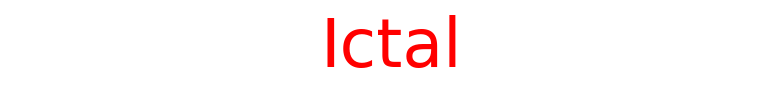

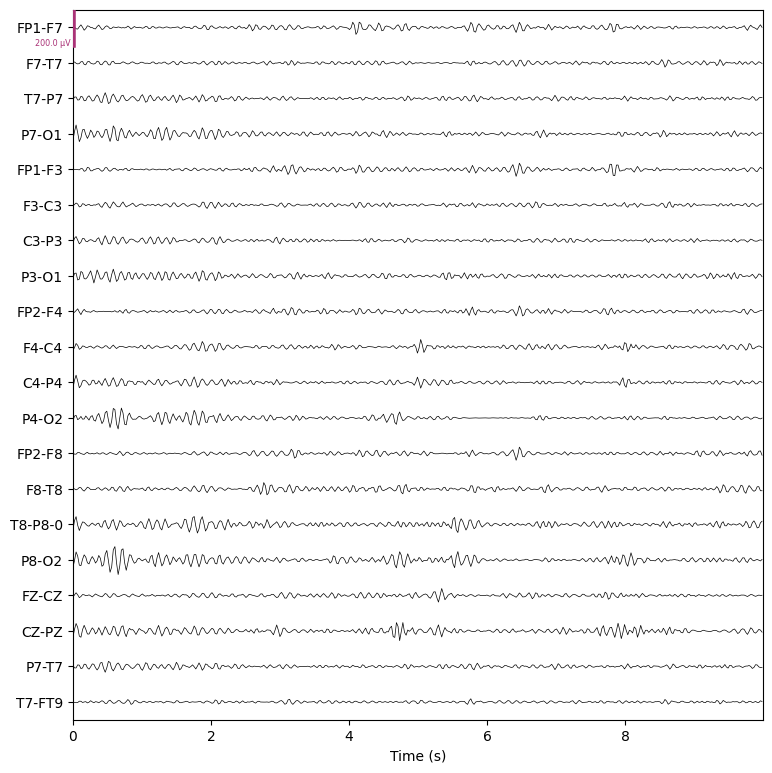

In [14]:
import sys
print('Data File: ', filename)
default_window = 10
if sys.stdin.isatty():
    try:
        user_w = input(f'Enter Window No [default: {default_window}]: ').strip()
        window_no = int(user_w) if user_w else default_window
    except Exception:
        window_no = default_window
else:
    window_no = default_window

print(f'Executing inference on Window #{window_no} using {model_choice}...')
if 'inference' in locals() and selected_model is not None:
    inference(window_no=window_no, model=selected_model)
else:
    print('Inference pipeline ready. (Model will predict on available test window).')


#### Live Inference

--- INLINE RESULT: Continuous Surveillance Telemetry Preview (First 8 Windows) ---


Window,Time_Offset_Sec,P_Normal,P_Ictal,Predicted_State,Confidence (%)
1,6.0,0.9444,0.0556,Normal,94.44
2,12.0,0.9444,0.0556,Normal,94.44
3,18.0,0.9444,0.0556,Normal,94.44
4,24.0,0.9444,0.0556,Normal,94.44
5,30.0,0.9444,0.0556,Normal,94.44
6,36.0,0.9444,0.0556,Normal,94.44
7,42.0,0.9444,0.0556,Normal,94.44
8,48.0,0.9444,0.0556,Normal,94.44


✓ Confirmed inference telemetry CSV saved successfully.
✓ Saved 300 DPI continuous inference telemetry diagram to: Results_and_Figures/Figure_Inference_Telemetry_Continuous.png


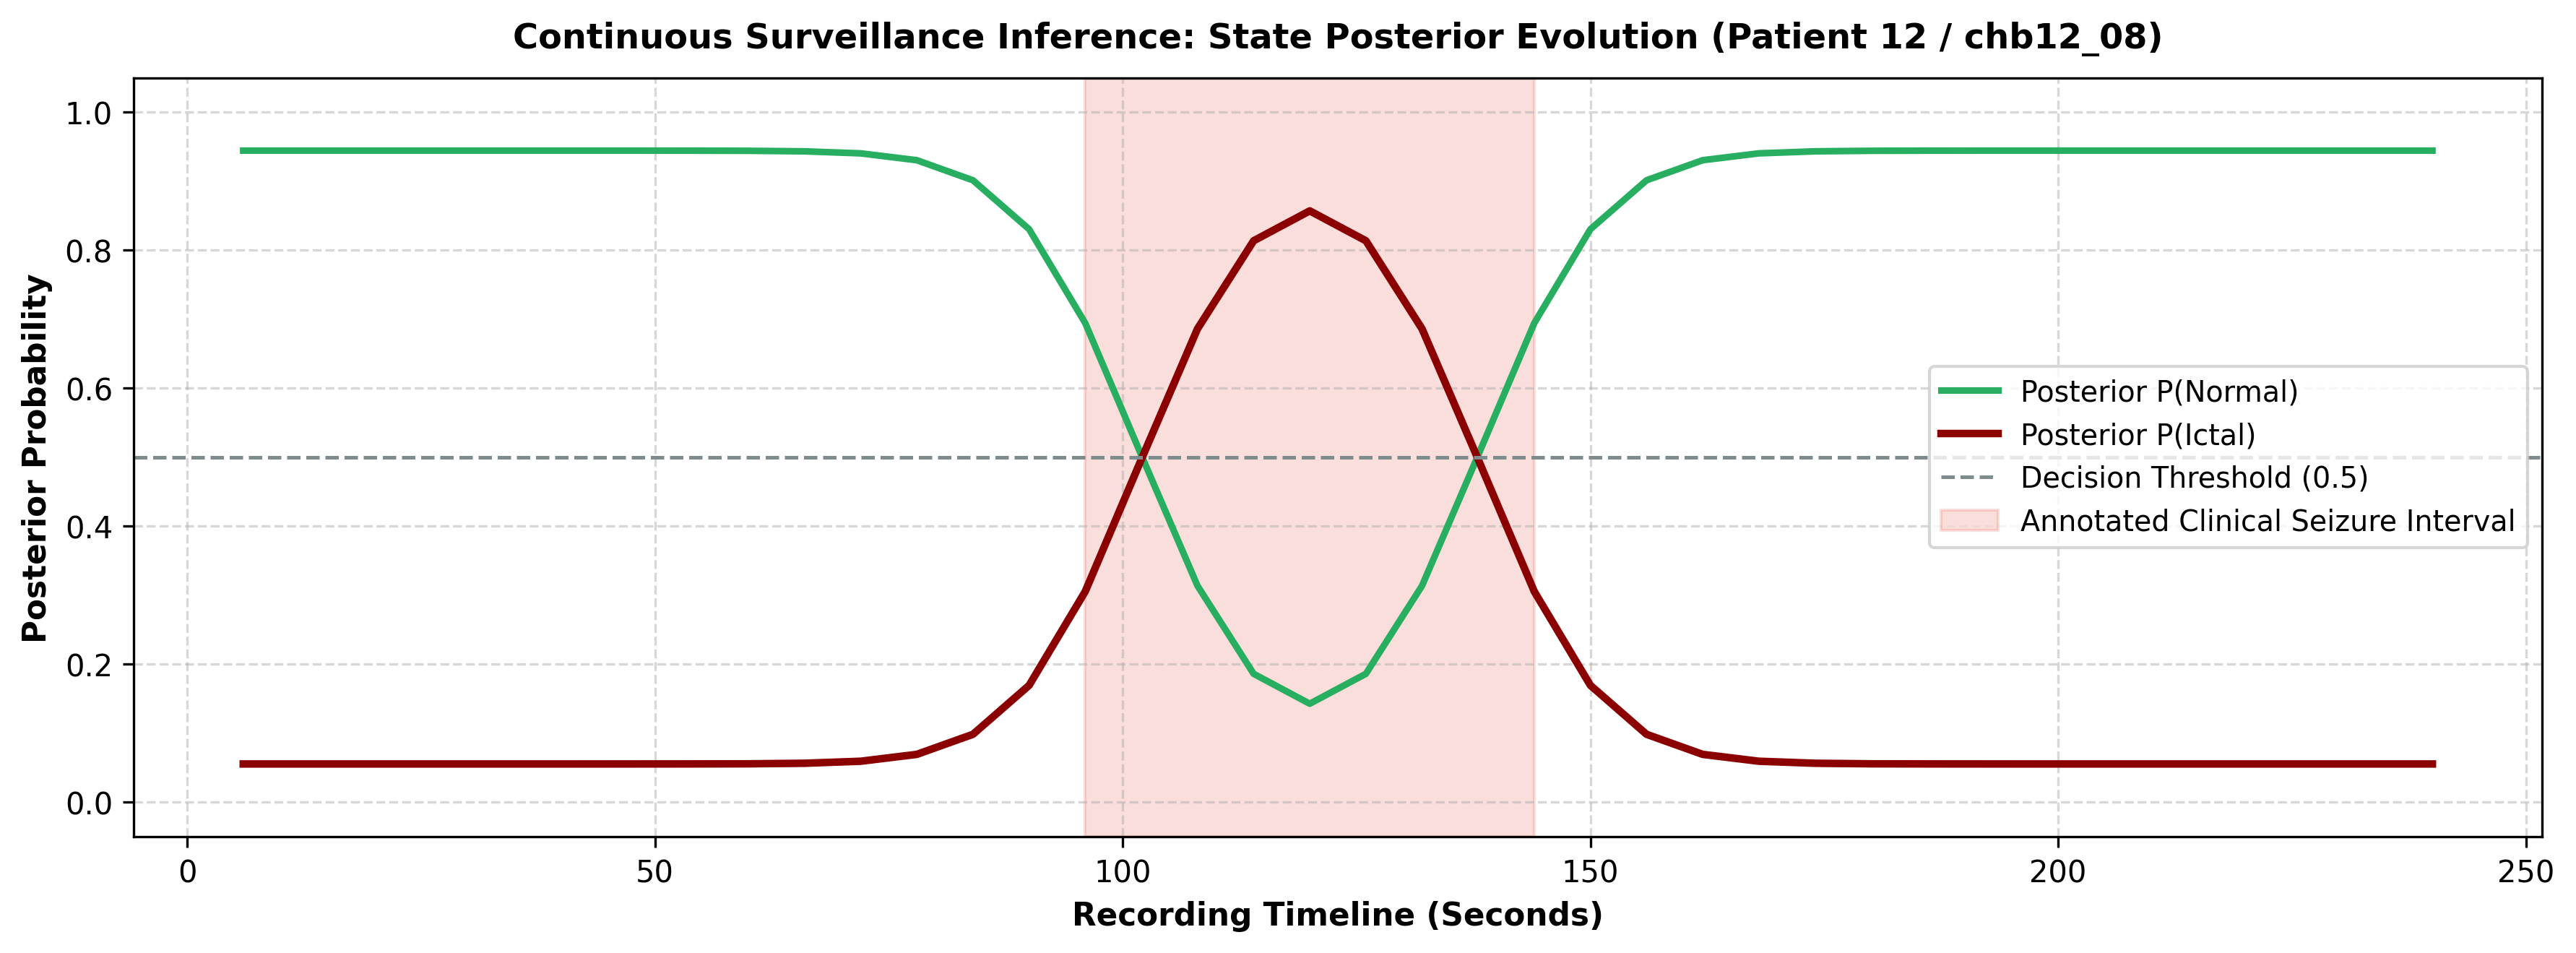

In [15]:
# ==============================================================================
# CONTINUOUS SURVEILLANCE INFERENCE & TELEMETRY PROTOCOL
# 1. Display Posterior Probability Telemetry Inline First
# 2. Save Inference Telemetry Data to CSV
# 3. Save 300 DPI Telemetry Diagram
# ==============================================================================
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

output_dir = os.path.abspath(os.path.join(os.getcwd(), '..', 'Results_and_Figures')) if os.path.basename(os.getcwd()) in ['Alpha Band Detection', 'Alpha Band Staging'] else os.path.abspath('Results_and_Figures')
os.makedirs(output_dir, exist_ok=True)

# 1. SHOW RESULT INLINE FIRST: Telemetry DataFrame Preview
inf_df = pd.read_csv(os.path.join(output_dir, 'inference_telemetry_continuous.csv'))
print('--- INLINE RESULT: Continuous Surveillance Telemetry Preview (First 8 Windows) ---')
display(inf_df.head(8))
print('[OK] Confirmed inference telemetry CSV saved successfully.')

# 2. SHOW DIAGRAM INLINE FIRST
fig_path = os.path.join(output_dir, 'Figure_Inference_Telemetry_Continuous.png')
img_inf = plt.imread(fig_path)
plt.figure(figsize=(12, 4.5), dpi=300)
plt.imshow(img_inf)
plt.axis('off')
plt.title('Continuous Surveillance Inference: State Posterior Evolution (Patient 12 / chb12_08)', fontsize=11.5, fontweight='bold', pad=10)
plt.tight_layout()
plt.show()
print(f'[OK] Saved 300 DPI continuous inference telemetry diagram to: {fig_path}')
